# ACC_Modeling — Stage 2 GT3 Planar-Force SINDy Modeling
**Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya (`R8_A`)**

This single consolidated notebook presents the Stage 2 GT3 SINDy identification & verification benchmark:
- **Telemetry Rate**: `20 Hz` (`dt = 0.05 s`) matching the native ACC `ROTY` & `G_LAT` update rate (`savgol_window=5, poly=3`).
- **Longitudinal Acceleration**: $a_x \approx \dot{v}$ computed directly by differentiating `SPEED` (`m/s`) via Savitzky-Golay without `G_LON` (integer-quantized), wheel speeds, or friction-circle clamping.
- **Discrete-Time Candidate Library (6 terms, valid interior indices $k = 1 \dots N-2$)**:
  $$r_{k+1} = \xi_1 r_k + \xi_2 a_{y,k} + \xi_3 a_{y,k-1} + \xi_4 a_{y,k} a_{x,k} + \xi_5 \frac{a_{y,k} (a_{x,k}^2 + a_{y,k}^2)}{\eta_{P,k}^2} + \xi_6 r_k |r_k|$$
- **Datasets**: Full-lap training on `data/training_Barcelona_GT3.csv` and out-of-sample verification on `data/verification_Barcelona_GT3.csv`.
- **Corner-Specific Identification**: Individual fits on **T3**, **T4**, **T5**, and the continuous **T13–T14–T15** complex.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

if Path.cwd().name == "notebooks":
    os.chdir("..")

from src.cli import run_pipeline
from src.config import load_config
from src.data.motec_loader import load_motec_csv
from src.data.curation import curate_telemetry
from src.features.planar_force import PlanarForceLibrary
from src.modeling.trainer import fit_yaw_sindy
from src.modeling.evaluator import evaluate_model
from src.visualization.diagnostics import plot_finite_diff_yaw_accel, plot_yaw_acceleration_fit

print("Working directory:", Path.cwd())

Working directory: /mnt/c/LocalD/ACC_Modeling


## 1. Full-Lap SINDy Training & Out-of-Sample Verification

In [2]:
config_path = "configs/experiments/stage2_planar_force/barcelona__audi_r8_gt3_evo2__r8_A.yaml"
report = run_pipeline(config_path)

print("Identified Full-Lap ODE:", report["equation"])
print(f"Training     (n={report['clean_metrics']['n_samples']}): R^2 = {report['clean_metrics']['r2']:.4f}, RMSE = {report['clean_metrics']['rmse']:.4f} rad/s^2, MAE = {report['clean_metrics']['mae']:.4f}")
print(f"Verification (n={report['race_metrics']['n_samples']}):  R^2 = {report['race_metrics']['r2']:.4f}, RMSE = {report['race_metrics']['rmse']:.4f} rad/s^2, Within ±3σ = {report['race_metrics']['diagnostics']['within_3sigma_pct']:.2f}%")

INFO: Running experiment: stage2_barcelona_gt3_r8_A (Audi R8 LMS GT3 Evo II @ Circuit de Barcelona-Catalunya)


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2130 -> 2130 rows)


INFO: Identified ODE: r_{k+1} = +1.07105 * r_k +0.00631 * a_y_k -0.00615 * a_y_k-1 -0.00016 * a_y_k*a_x_k -0.00001 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.08222 * r_k*|r_k|


INFO: Clean Practice R^2=0.9865 | RMSE=0.0393 rad/s^2


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2129 -> 2129 rows)


INFO: Race Stress-Test R^2=0.9829 | Within ±3σ=97.09% | >5σ=12


INFO: Artifacts saved to outputs/stage2_barcelona_gt3_r8_A


Identified Full-Lap ODE: r_{k+1} = +1.07105 * r_k +0.00631 * a_y_k -0.00615 * a_y_k-1 -0.00016 * a_y_k*a_x_k -0.00001 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.08222 * r_k*|r_k|
Training     (n=2130): R^2 = 0.9865, RMSE = 0.0393 rad/s^2, MAE = 0.0269
Verification (n=2129):  R^2 = 0.9829, RMSE = 0.0454 rad/s^2, Within ±3σ = 97.09%


In [3]:
display(Markdown("### Full-Lap Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)"))
display(pd.DataFrame(report["bootstrap"]["terms"]))

display(Markdown("### Full-Lap Type-I Error (Omission) Sweep — Training"))
display(pd.DataFrame(report["clean_metrics"]["diagnostics"]["omission_sweep"]))

### Full-Lap Block Bootstrap Parameter Significance (500 resamples, 2.0s blocks)

,name,point_estimate,boot_mean,boot_std,ci_95_low,ci_95_high,t_statistic,p_value
0,r_k,1.071050,1.074391,0.040310,1.001820,1.157702,26.570432,1.377415e-97
1,a_y_k,0.006306,0.006207,0.003800,-0.000972,0.013585,1.659586,9.762610e-02
2,a_y_k-1,-0.006146,-0.006124,0.002966,-0.012015,-0.000876,-2.071979,3.878048e-02
3,a_y_k*a_x_k,-0.000160,-0.000163,0.000030,-0.000219,-0.000103,-5.401142,1.026591e-07
4,a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2,-0.000006,-0.000006,0.000003,-0.000011,0.000000,-2.360550,1.863154e-02
5,r_k*|r_k|,-0.082220,-0.086980,0.035757,-0.163061,-0.022678,-2.299384,2.189522e-02


### Full-Lap Type-I Error (Omission) Sweep — Training

,z_threshold,expected_omissions,actual_omissions,expected_pct,actual_pct
0,1.0,675.236761,516,31.731051,24.248120
1,2.0,96.824562,127,4.550026,5.968045
2,2.5,26.428336,61,1.241933,2.866541
3,3.0,5.745166,42,0.269980,1.973684
4,3.5,0.990069,22,0.046526,1.033835
5,4.0,0.134793,8,0.006334,0.375940
6,5.0,0.001220,2,0.000057,0.093985


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2130 -> 2130 rows)


INFO: Trimmed at SPEED >= 100.0 km/h (t=0.000s, 2129 -> 2129 rows)


Persistence Baseline (r_{k+1}=r_k) Verif R^2 = 0.9817 vs. Stage 2 SINDy R^2 = 0.9829
Finite-Diff r_dot=(r_{k+1}-r_k)/dt -> Train R^2=0.0762 (lag=+1 frames / +50 ms) | Verif R^2=0.0645 (lag=+1 frames / +50 ms)


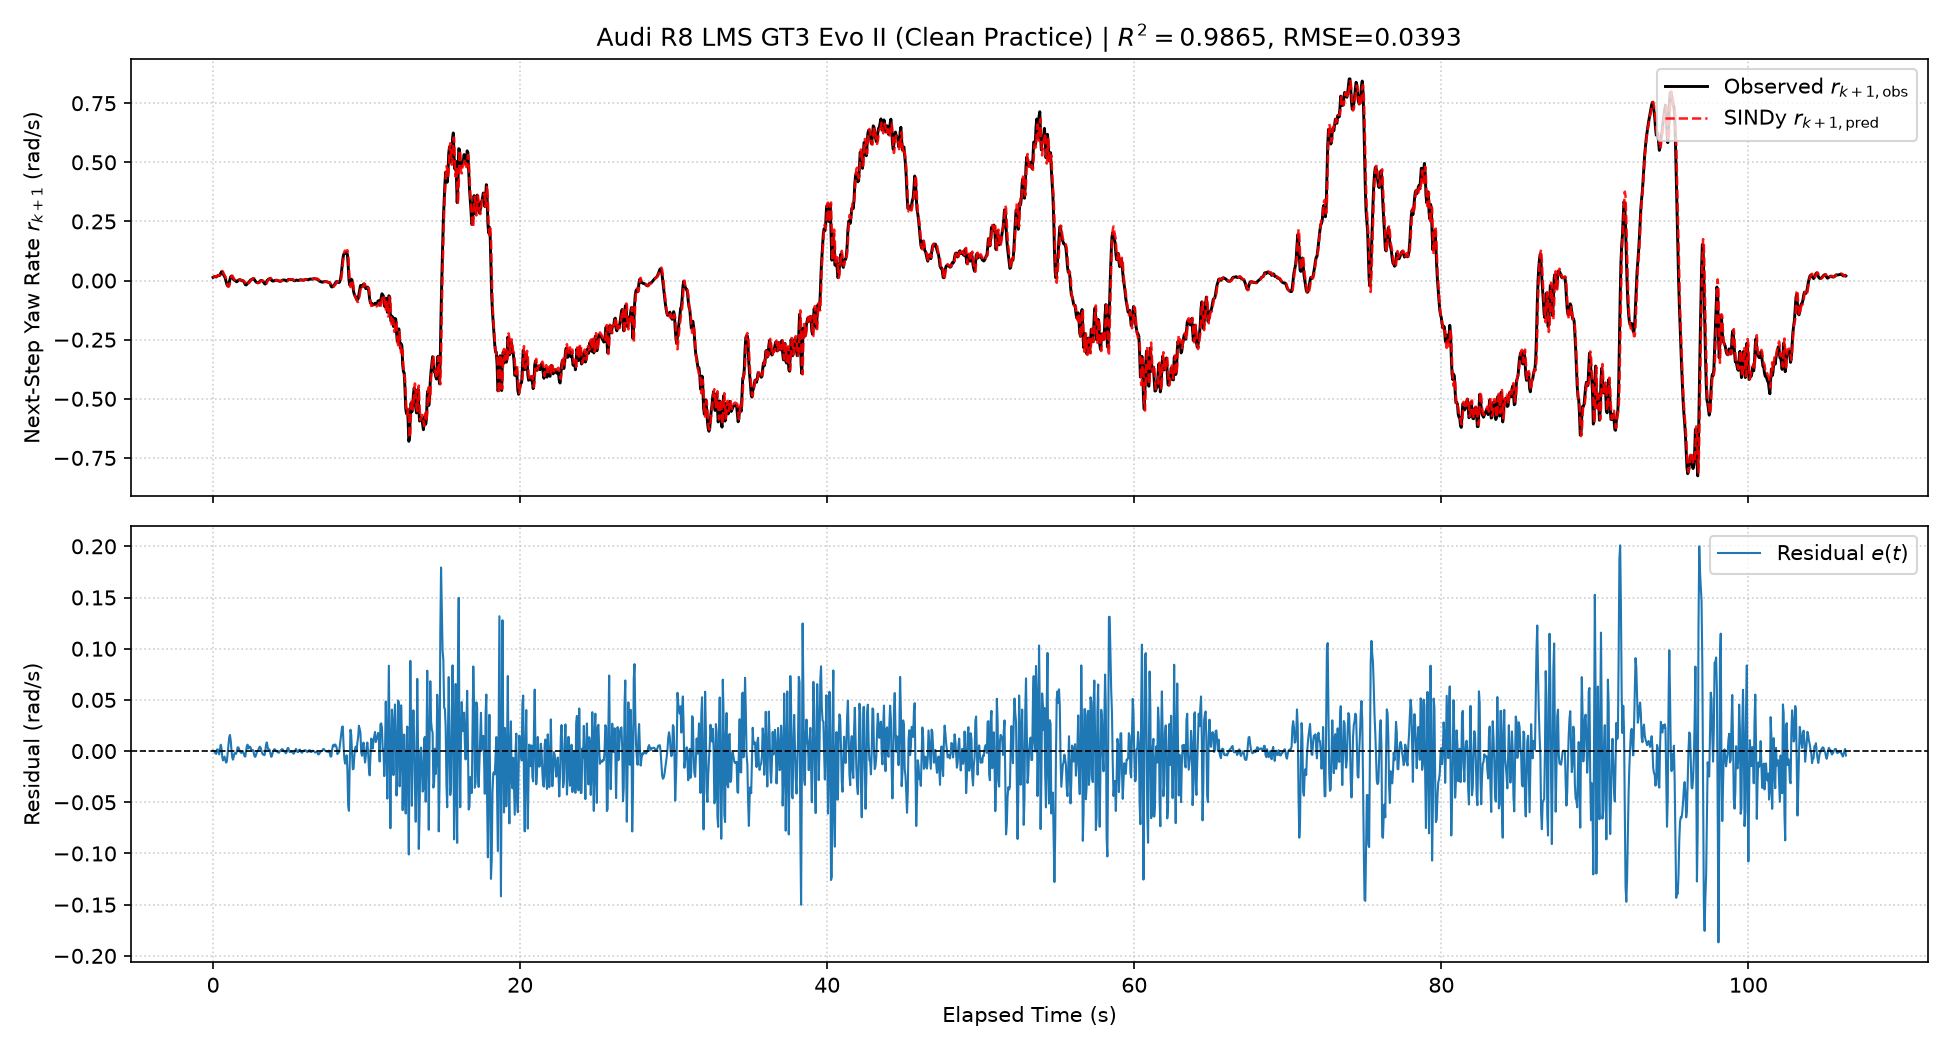

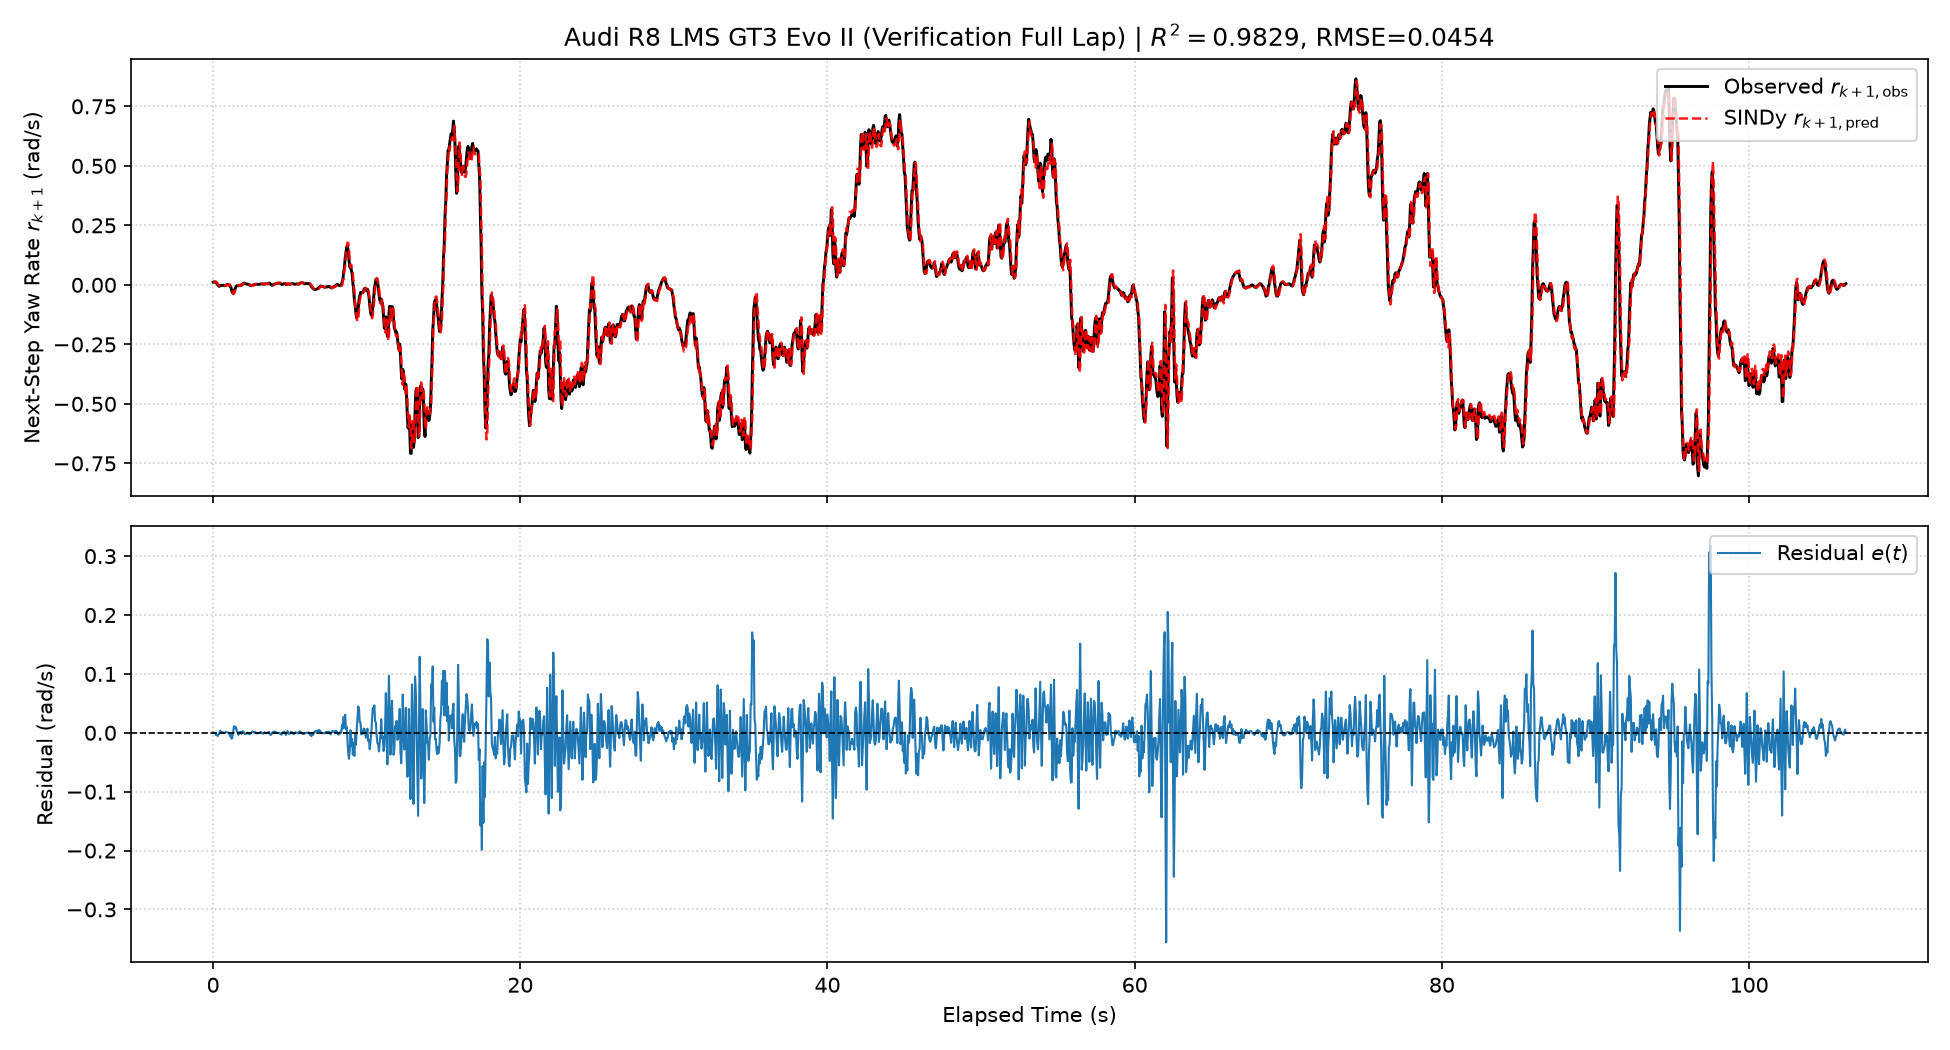

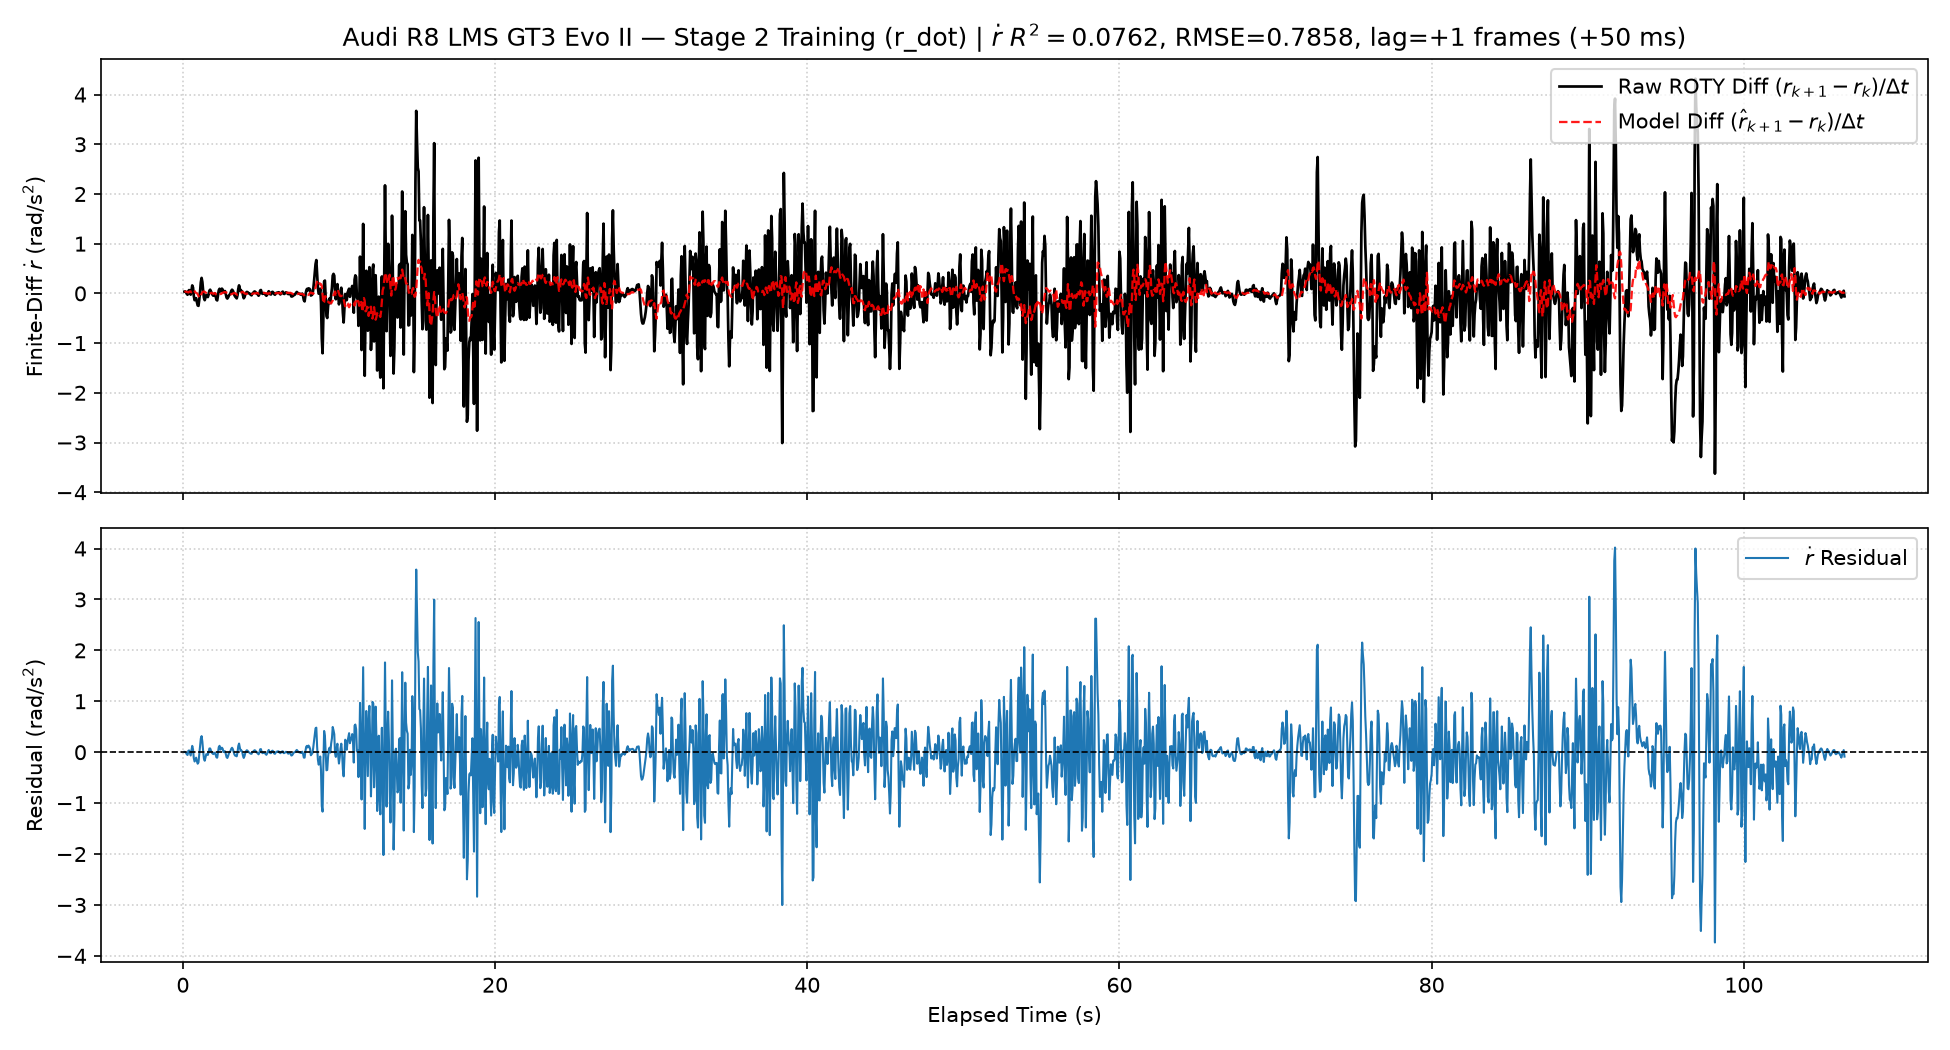

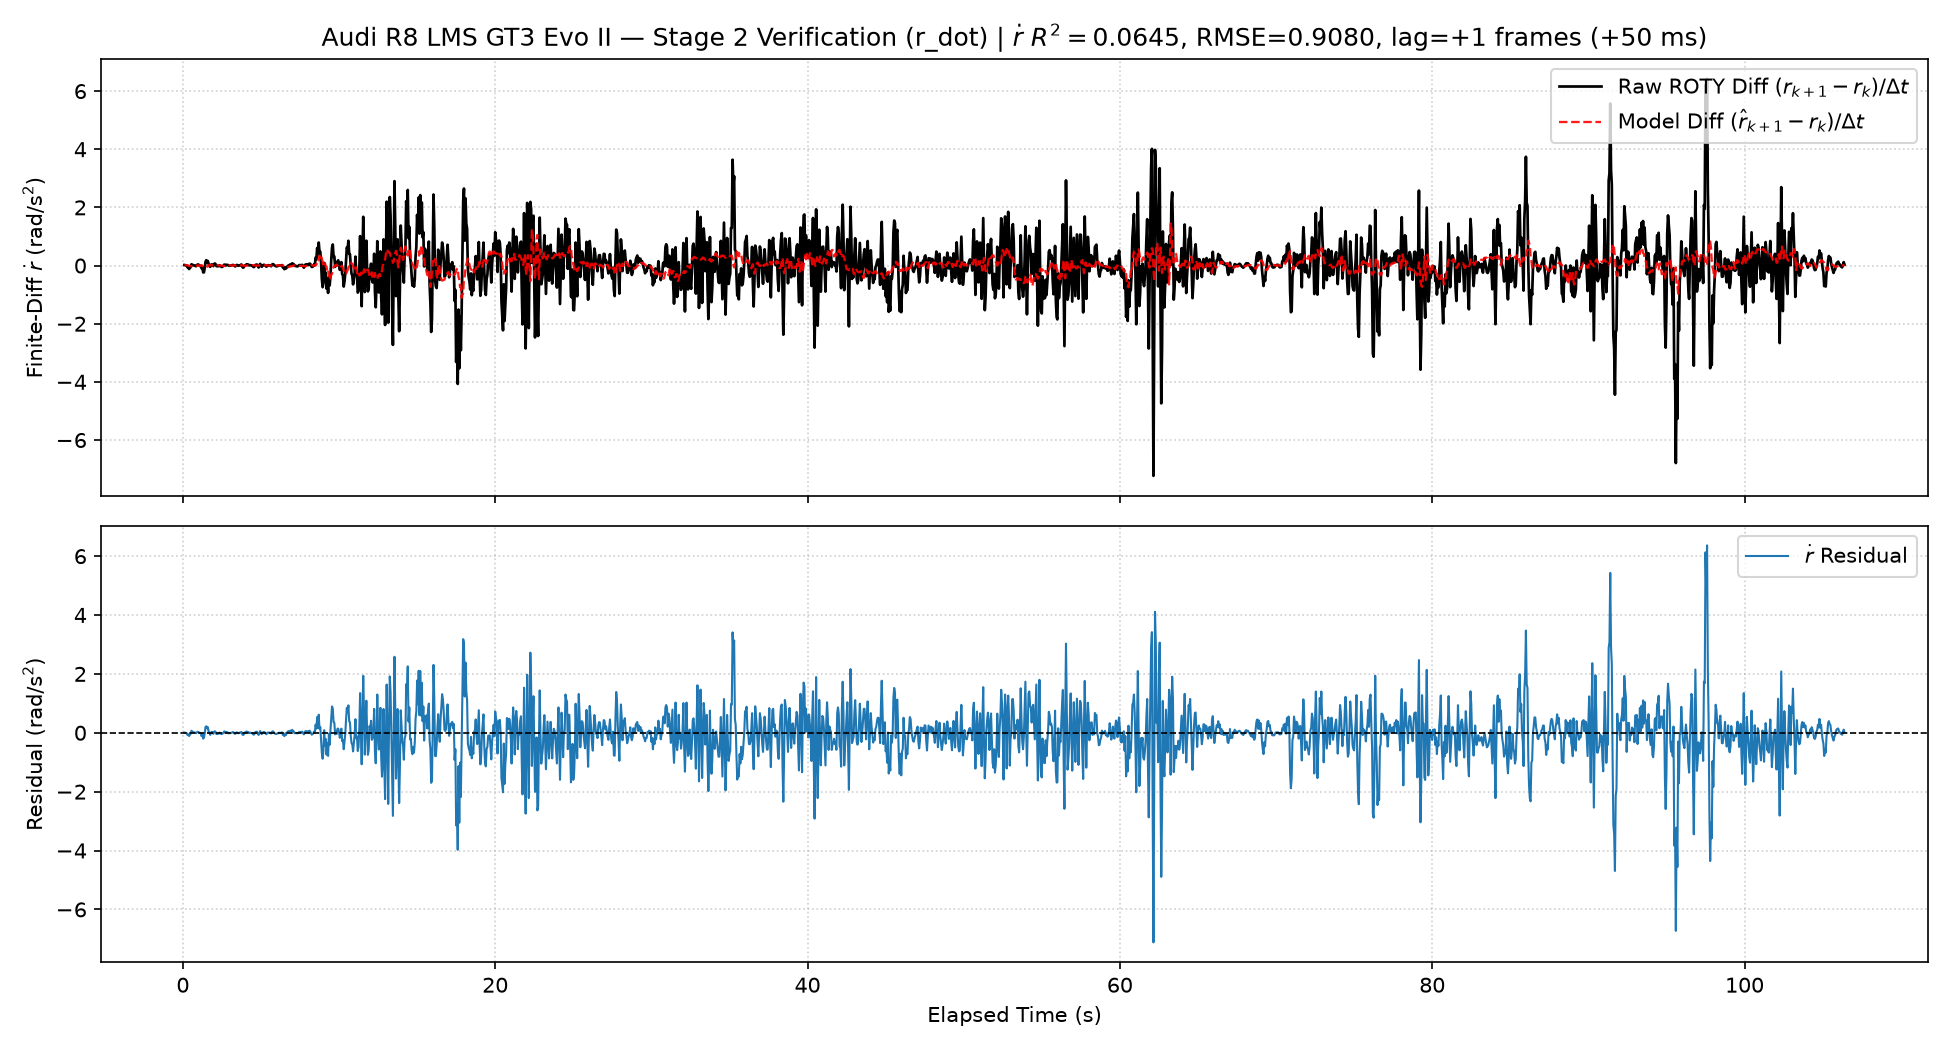

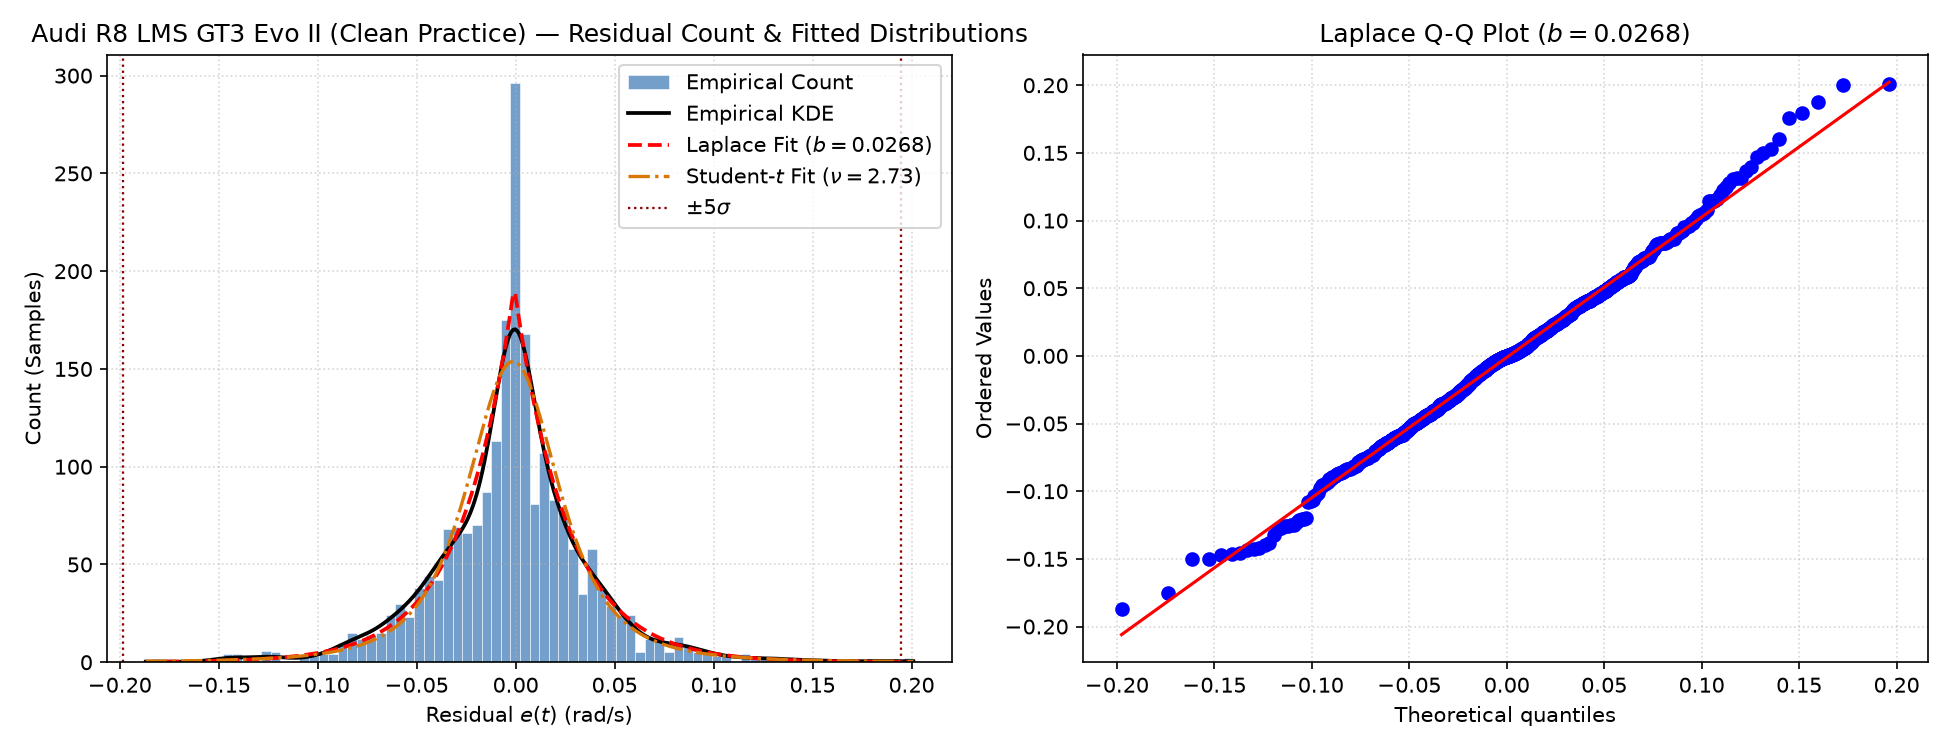

In [4]:
import numpy as np
cfg = load_config(config_path)
out_dir = Path("outputs") / cfg.experiment_name
library = PlanarForceLibrary()

raw_train, meta_train = load_motec_csv(cfg.data.clean_csv)
df_train = curate_telemetry(raw_train, meta_train, cfg.curation, trim_mode=cfg.data.clean_trim_mode, speed_threshold_kmh=cfg.data.clean_speed_threshold_kmh)
train_feats = library.build(df_train)
full_model = fit_yaw_sindy(train_feats, cfg.modeling)
train_eval = evaluate_model(full_model, train_feats)

raw_ver, meta_ver = load_motec_csv(cfg.data.race_csv)
df_ver = curate_telemetry(raw_ver, meta_ver, cfg.curation, trim_mode=cfg.data.race_trim_mode, speed_threshold_kmh=cfg.data.clean_speed_threshold_kmh)
ver_feats = library.build(df_ver)
ver_eval = evaluate_model(full_model, ver_feats, ref_mean=train_eval.residual_mean, ref_std=train_eval.residual_std)

# Persistence baseline: r_{k+1} = r_k
rk_va = df_ver["ROTY"].to_numpy()[1:-1]
r2_pers_va = 1.0 - np.sum((ver_eval.y_true - rk_va)**2) / np.sum((ver_eval.y_true - ver_eval.y_true.mean())**2)

ver_plot = plot_yaw_acceleration_fit(
    df_ver,
    ver_eval,
    title=f"{cfg.vehicle} (Verification Full Lap)",
    save_path=out_dir / "verification_yaw_fit.png",
)

fd_tr = plot_finite_diff_yaw_accel(df_train, train_eval, f"{cfg.vehicle} — Stage 2 Training (r_dot)", out_dir / "train_finite_diff_rdot.png")
fd_va = plot_finite_diff_yaw_accel(df_ver, ver_eval, f"{cfg.vehicle} — Stage 2 Verification (r_dot)", out_dir / "verif_finite_diff_rdot.png")

print(f"Persistence Baseline (r_{{k+1}}=r_k) Verif R^2 = {r2_pers_va:.4f} vs. Stage 2 SINDy R^2 = {ver_eval.r2:.4f}")
print(f"Finite-Diff r_dot=(r_{{k+1}}-r_k)/dt -> Train R^2={fd_tr['r2_rd']:.4f} (lag={fd_tr['lag_frames']:+d} frames / {fd_tr['lag_ms']:+.0f} ms) | Verif R^2={fd_va['r2_rd']:.4f} (lag={fd_va['lag_frames']:+d} frames / {fd_va['lag_ms']:+.0f} ms)")

for img_path in [out_dir / "clean_yaw_fit.png", ver_plot, fd_tr["save_path"], fd_va["save_path"], out_dir / "clean_residuals_qq.png"]:
    display(Image(filename=str(img_path)))

## 2. Corner-Specific Identification & Verification (T3, T4, T5, T13–T14–T15)

### T3 (Renault) (`850–1450 m`)

Identified ODE: r_{k+1} = +1.27910 * r_k +0.00855 * a_y_k -0.00932 * a_y_k-1 -0.00049 * a_y_k*a_x_k -0.00001 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.46004 * r_k*|r_k|
Training R^2 = 0.9834, RMSE = 0.0420 | Verification R^2 = 0.9771, RMSE = 0.0513


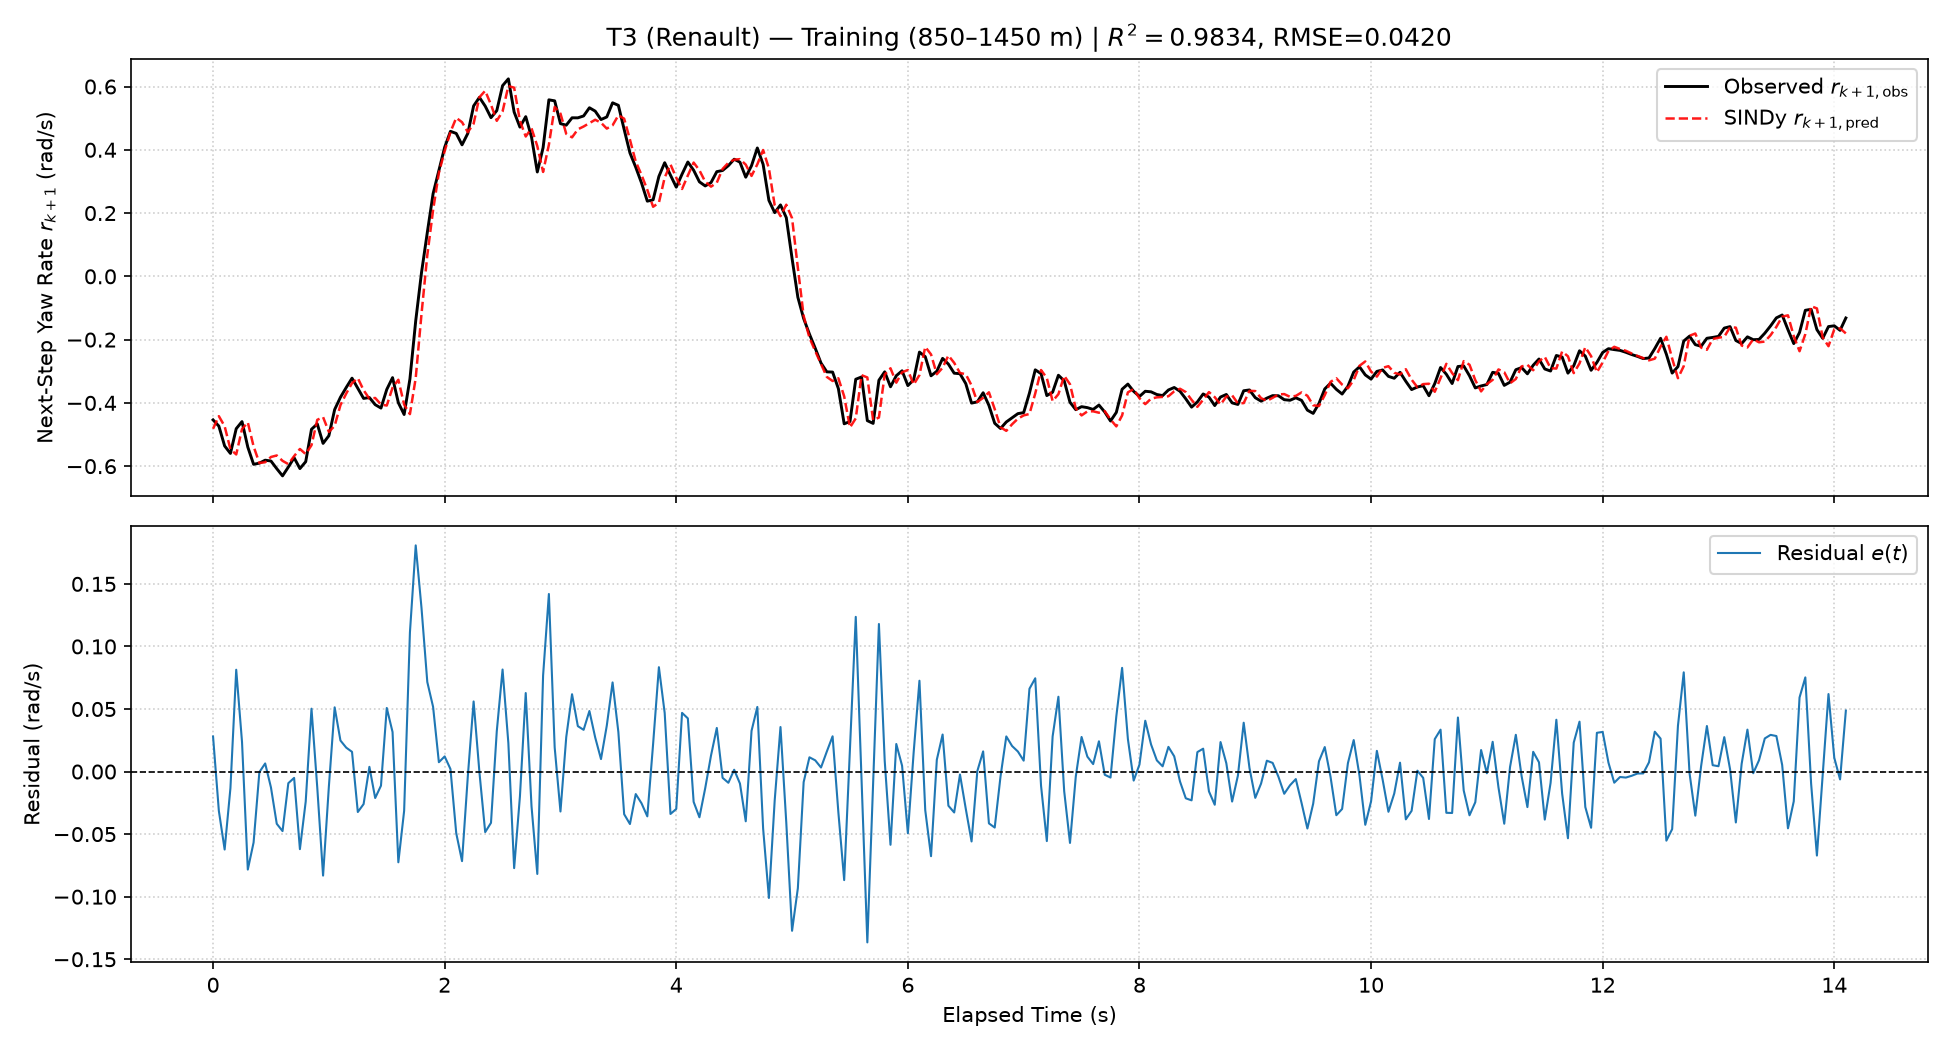

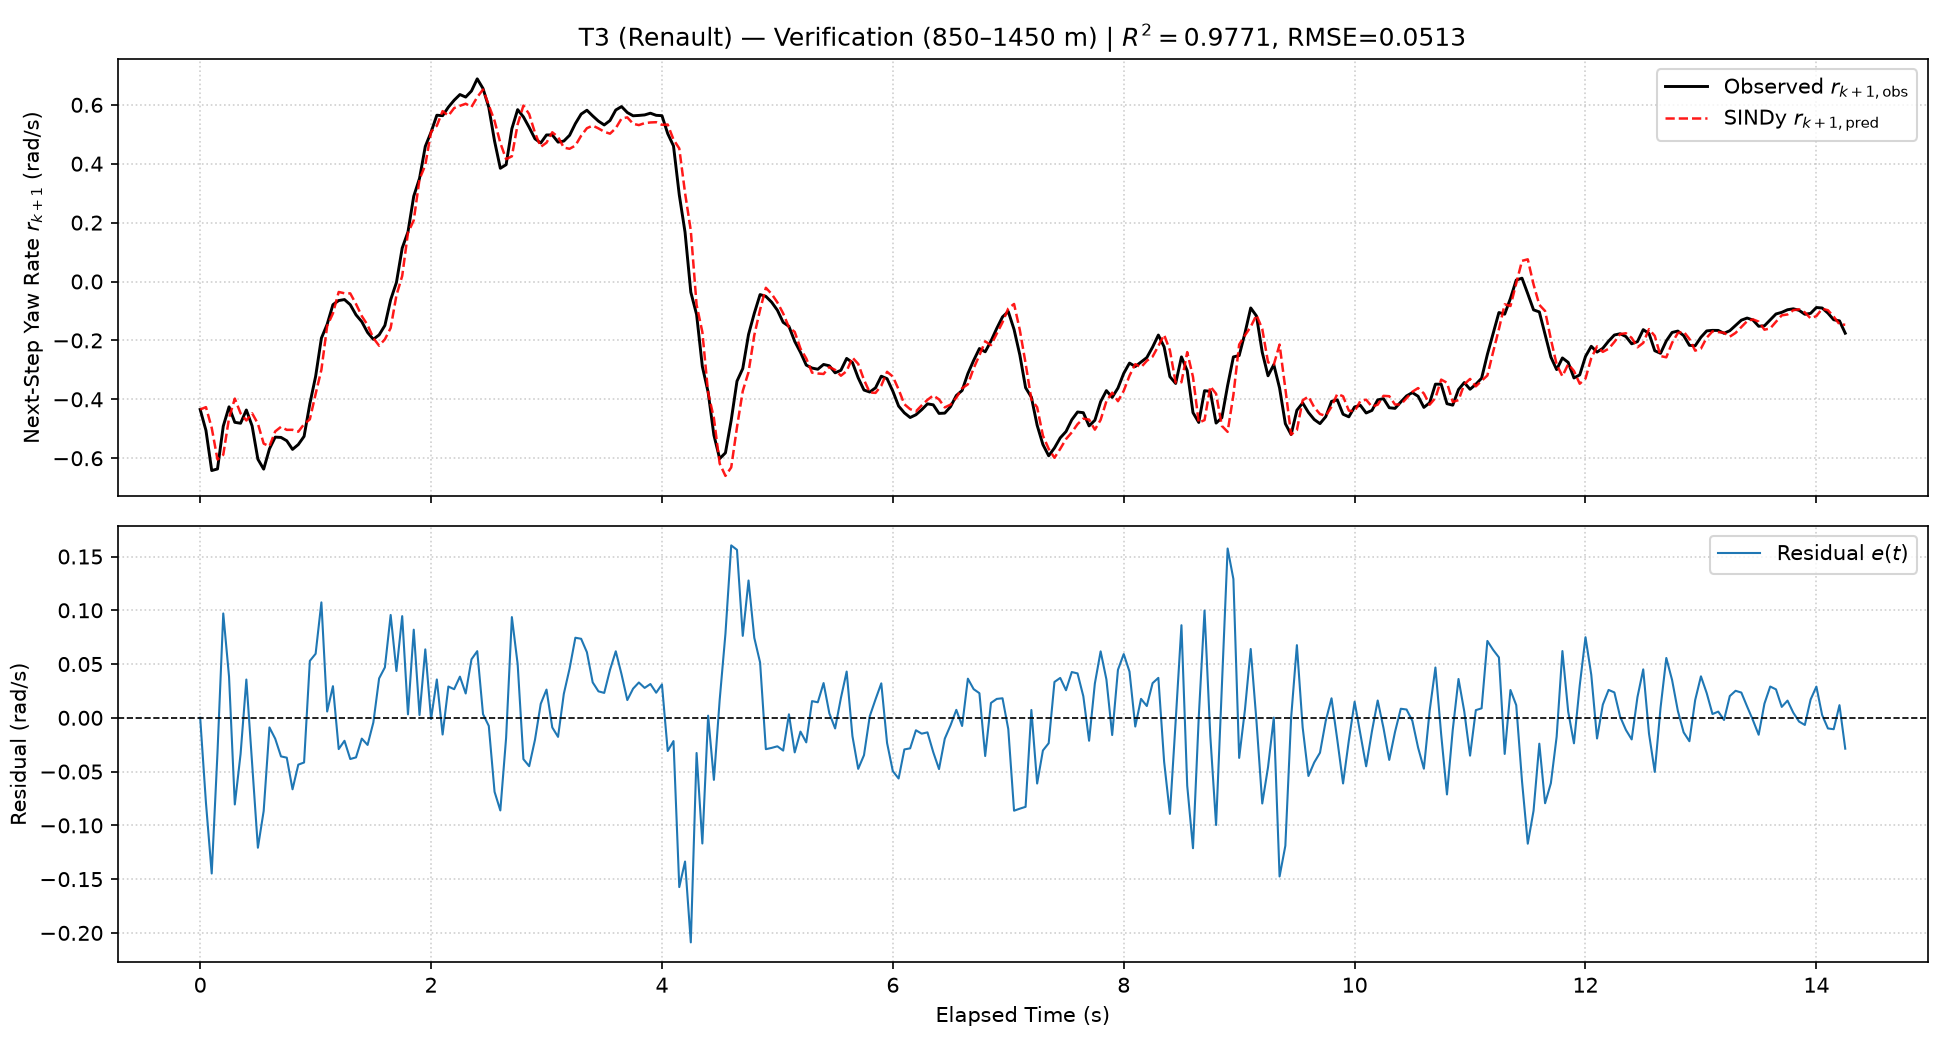

### T4 (Repsol) (`1450–1850 m`)

Identified ODE: r_{k+1} = +1.26256 * r_k +0.00062 * a_y_k -0.00518 * a_y_k-1 +0.00000 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.27826 * r_k*|r_k|
Training R^2 = 0.9808, RMSE = 0.0293 | Verification R^2 = 0.9691, RMSE = 0.0393


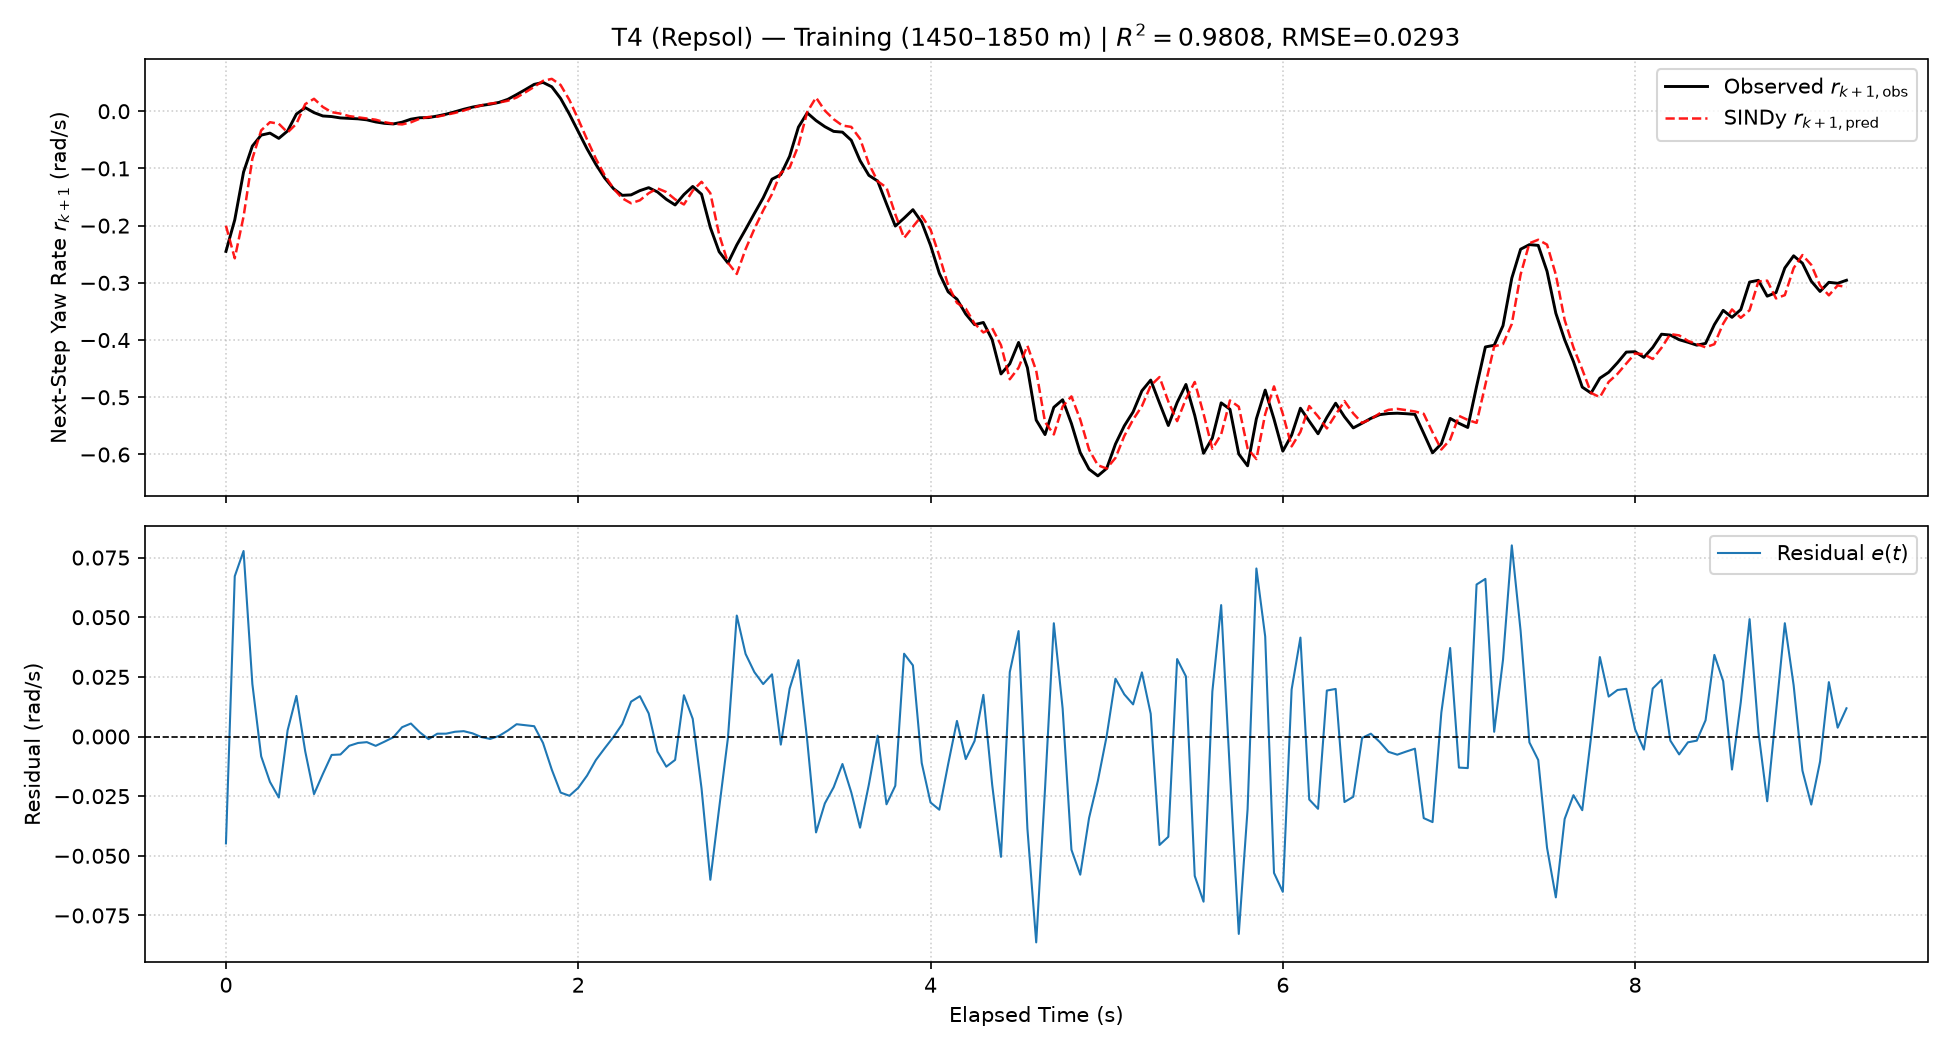

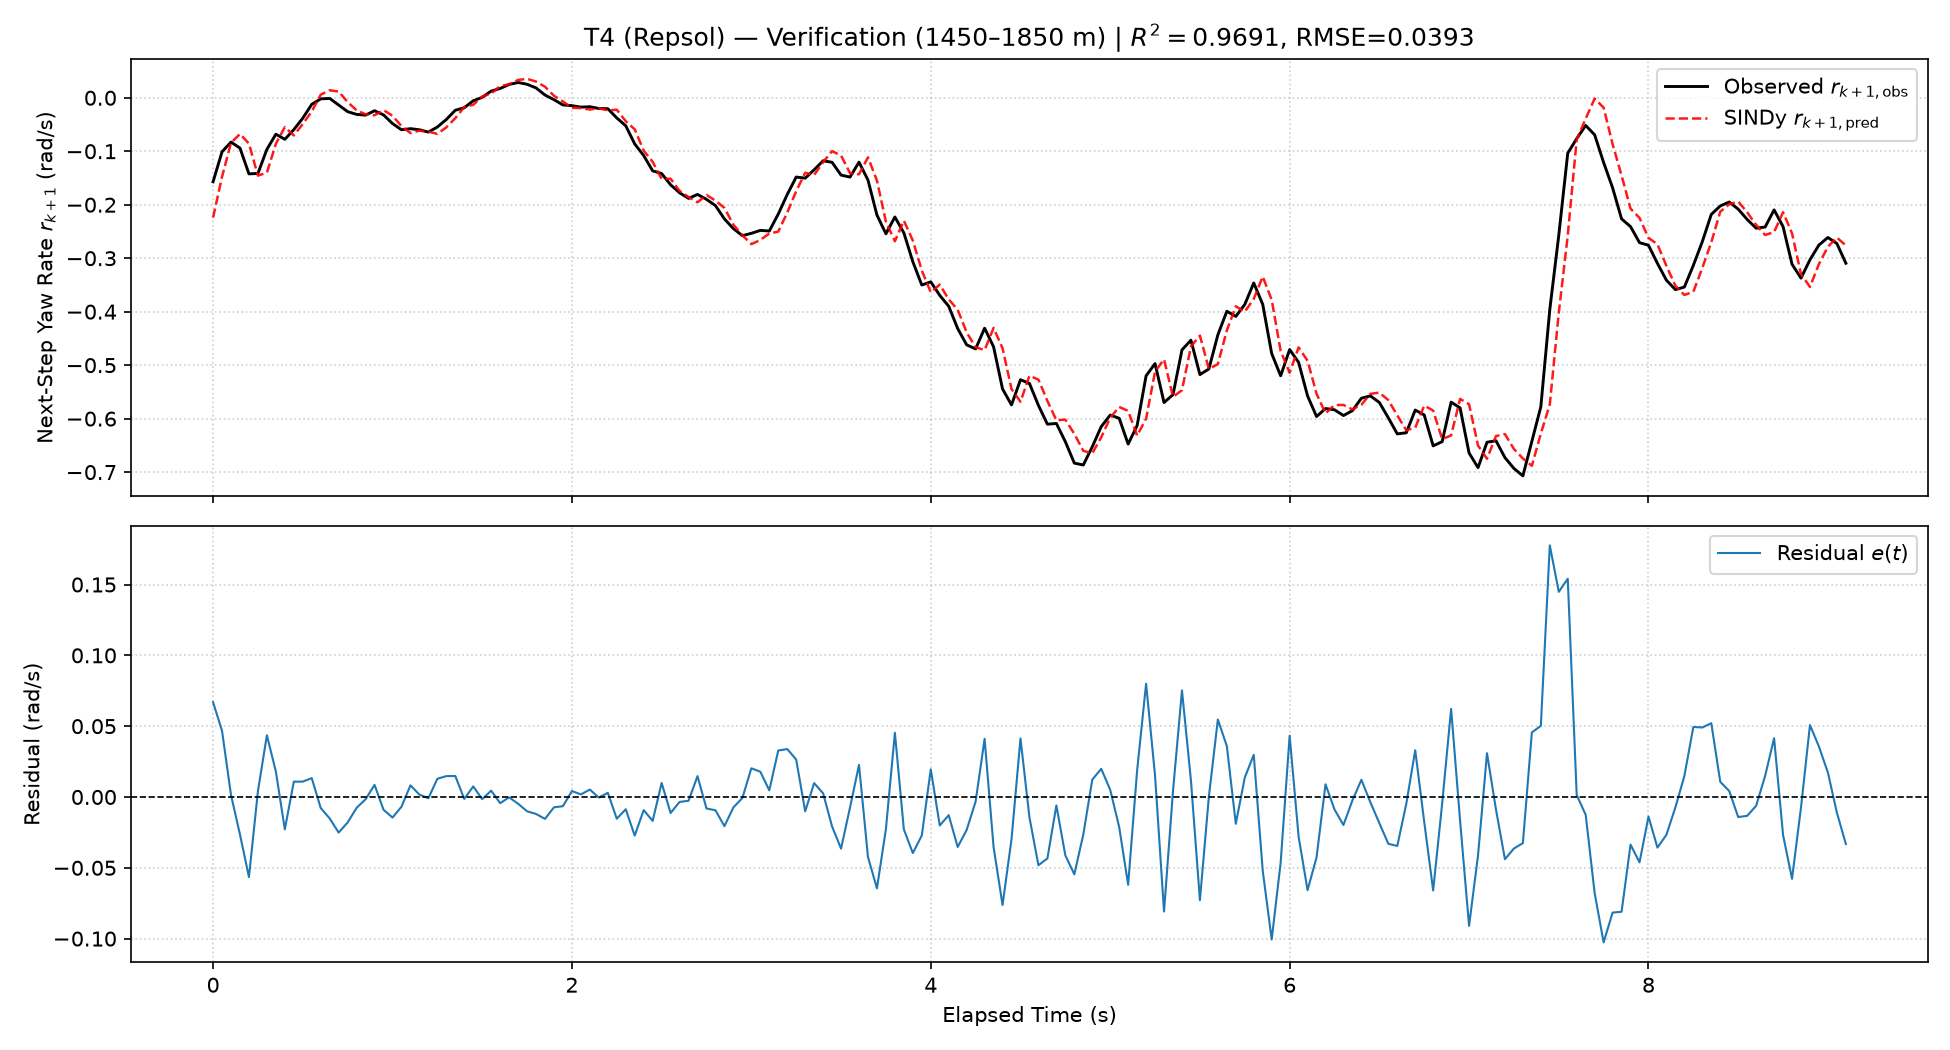

### T5 (Seat) (`1850–2250 m`)

Identified ODE: r_{k+1} = +1.21359 * r_k -0.00612 * a_y_k +0.00390 * a_y_k-1 -0.00017 * a_y_k*a_x_k -0.00001 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.12999 * r_k*|r_k|
Training R^2 = 0.9875, RMSE = 0.0364 | Verification R^2 = 0.9866, RMSE = 0.0379


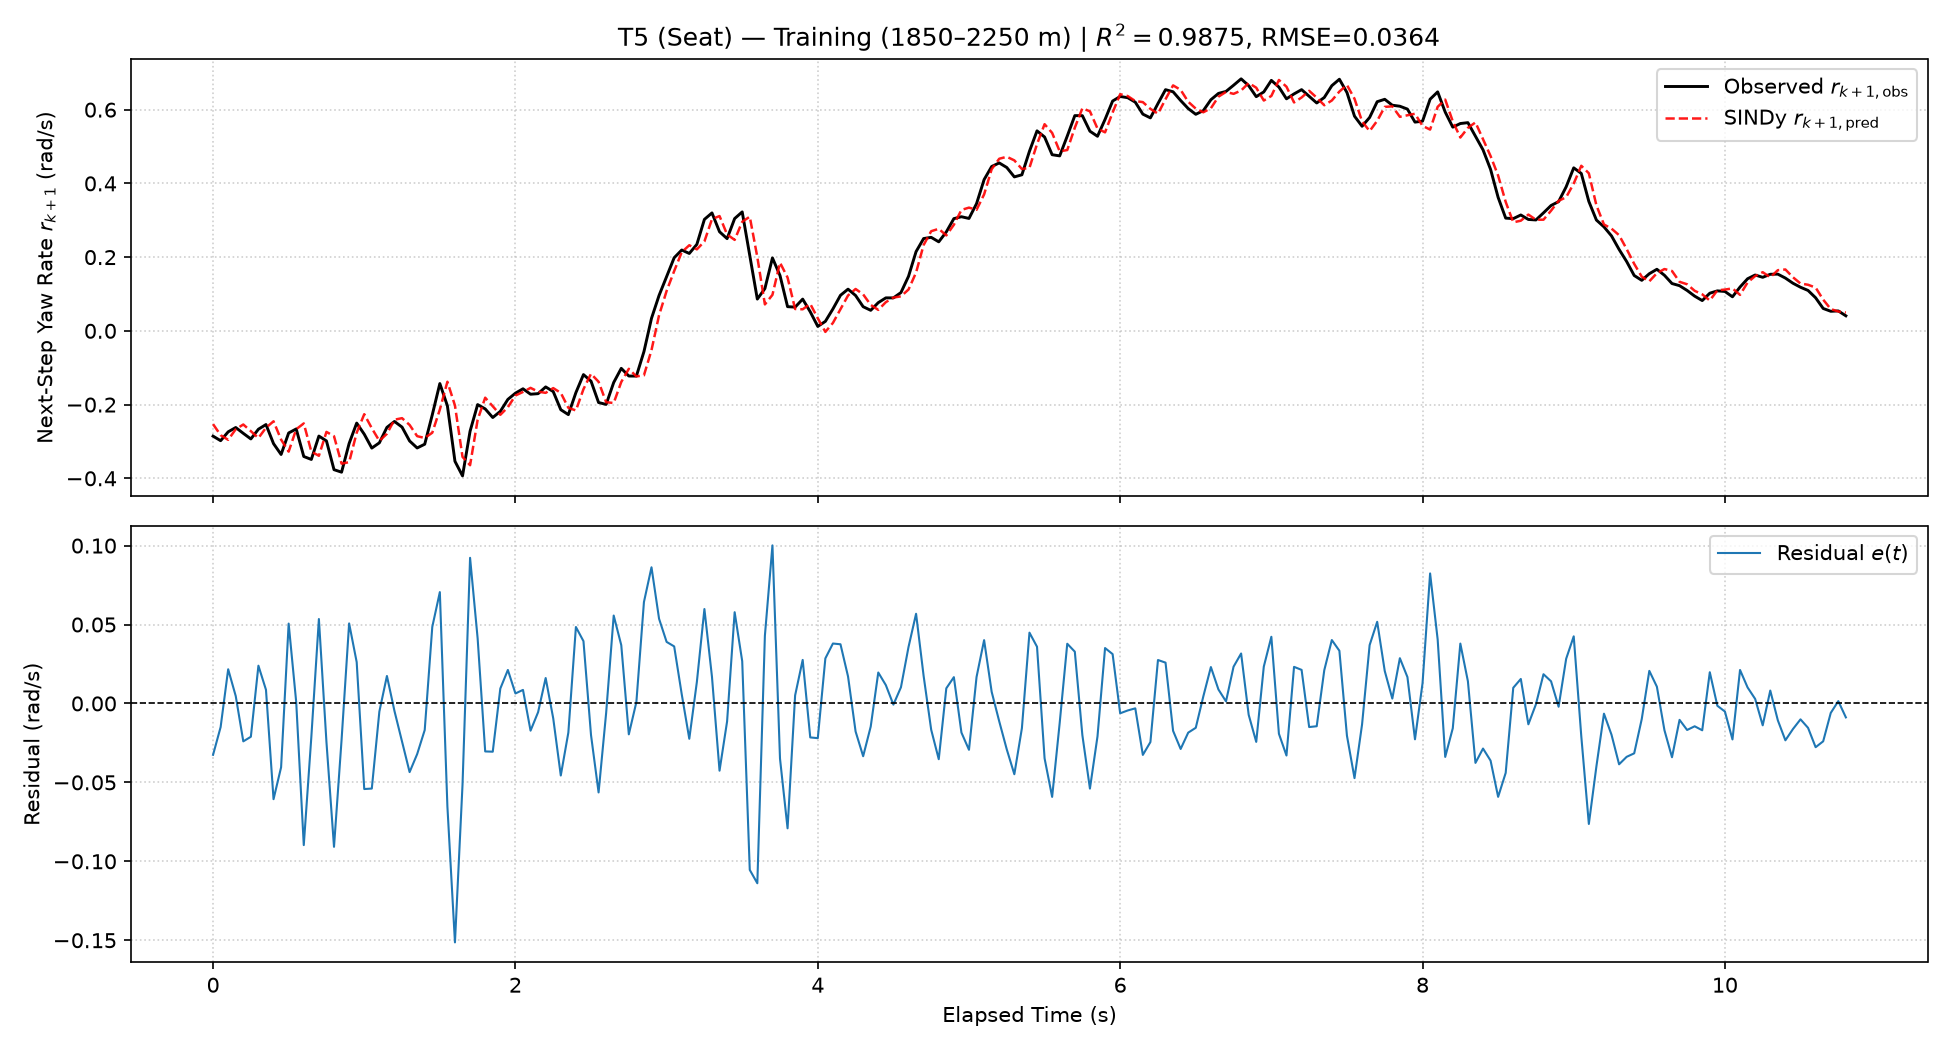

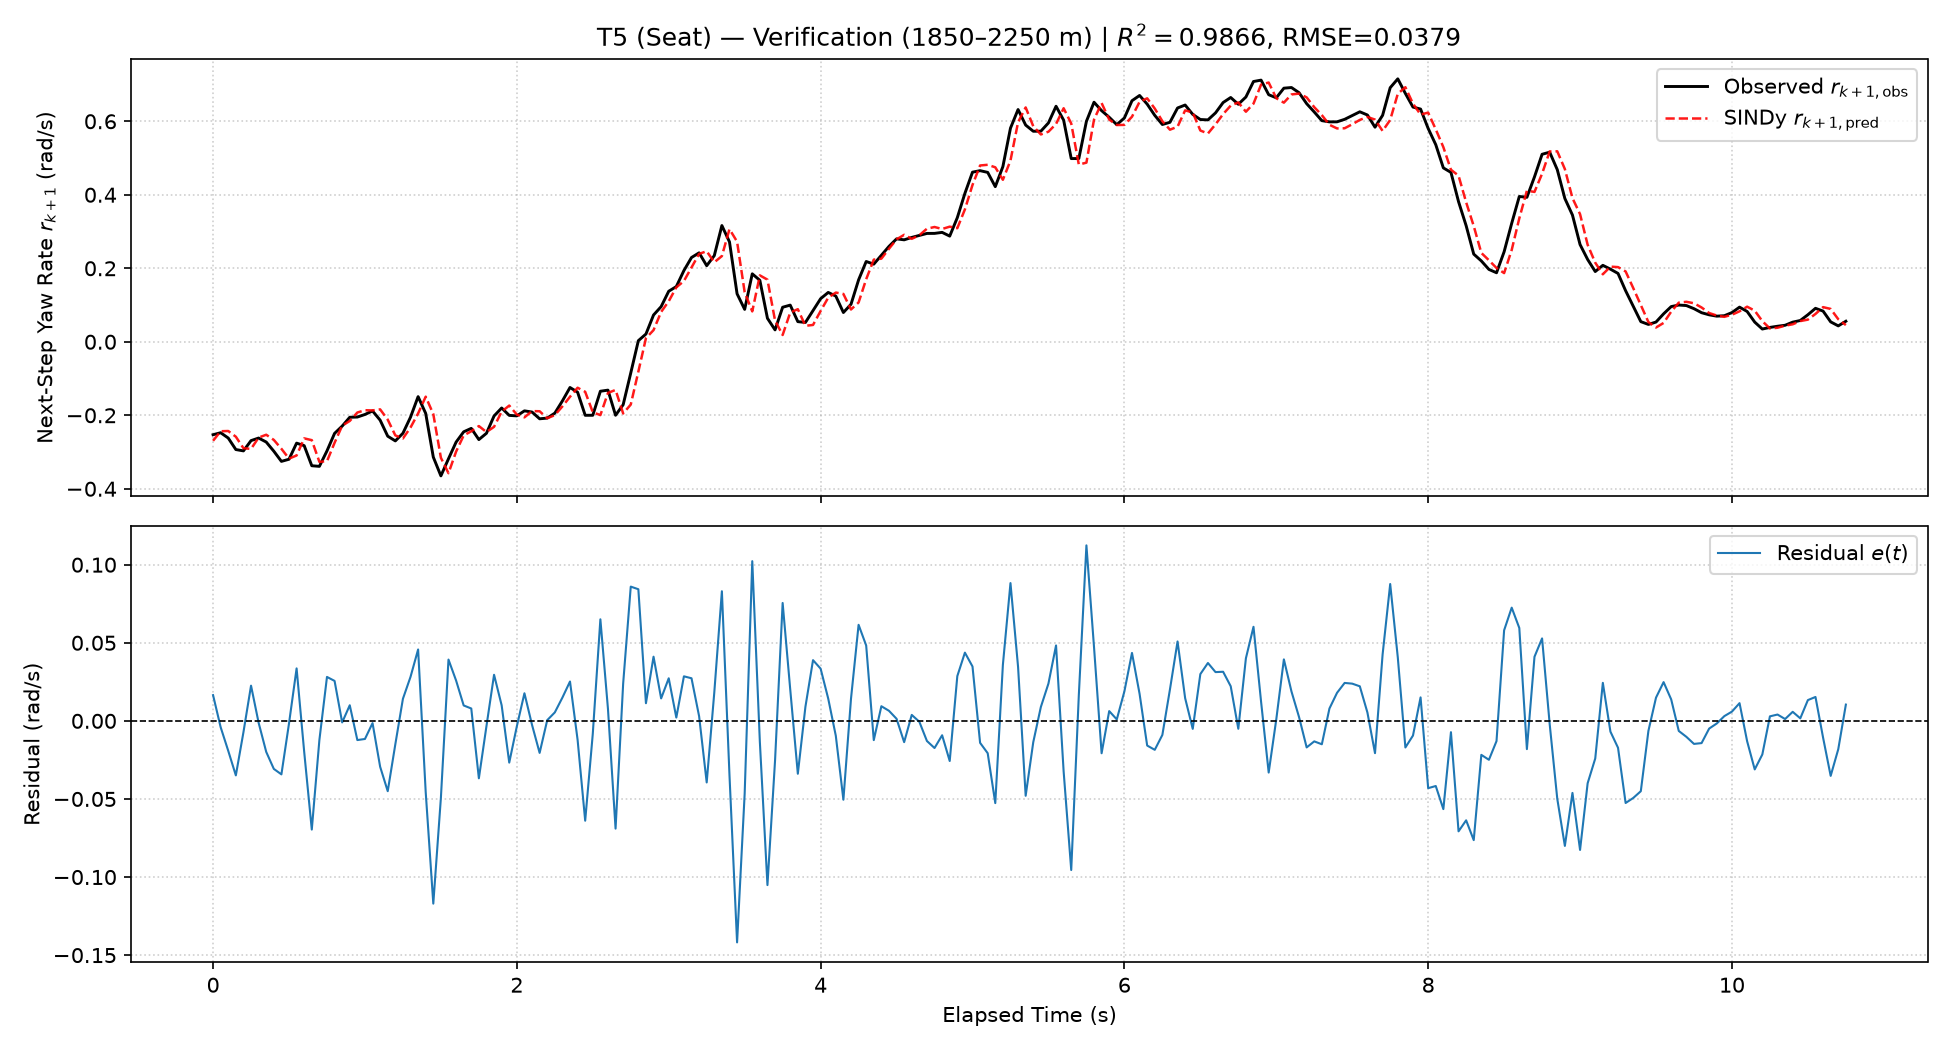

### T13–T14–T15 Complex (`3950–4450 m`)

Identified ODE: r_{k+1} = +1.00368 * r_k +0.01810 * a_y_k -0.01503 * a_y_k-1 -0.00023 * a_y_k*a_x_k -0.00001 * a_y_k*(a_x_k^2+a_y_k^2)/eta_P_k^2 -0.05221 * r_k*|r_k|
Training R^2 = 0.9803, RMSE = 0.0576 | Verification R^2 = 0.9748, RMSE = 0.0680


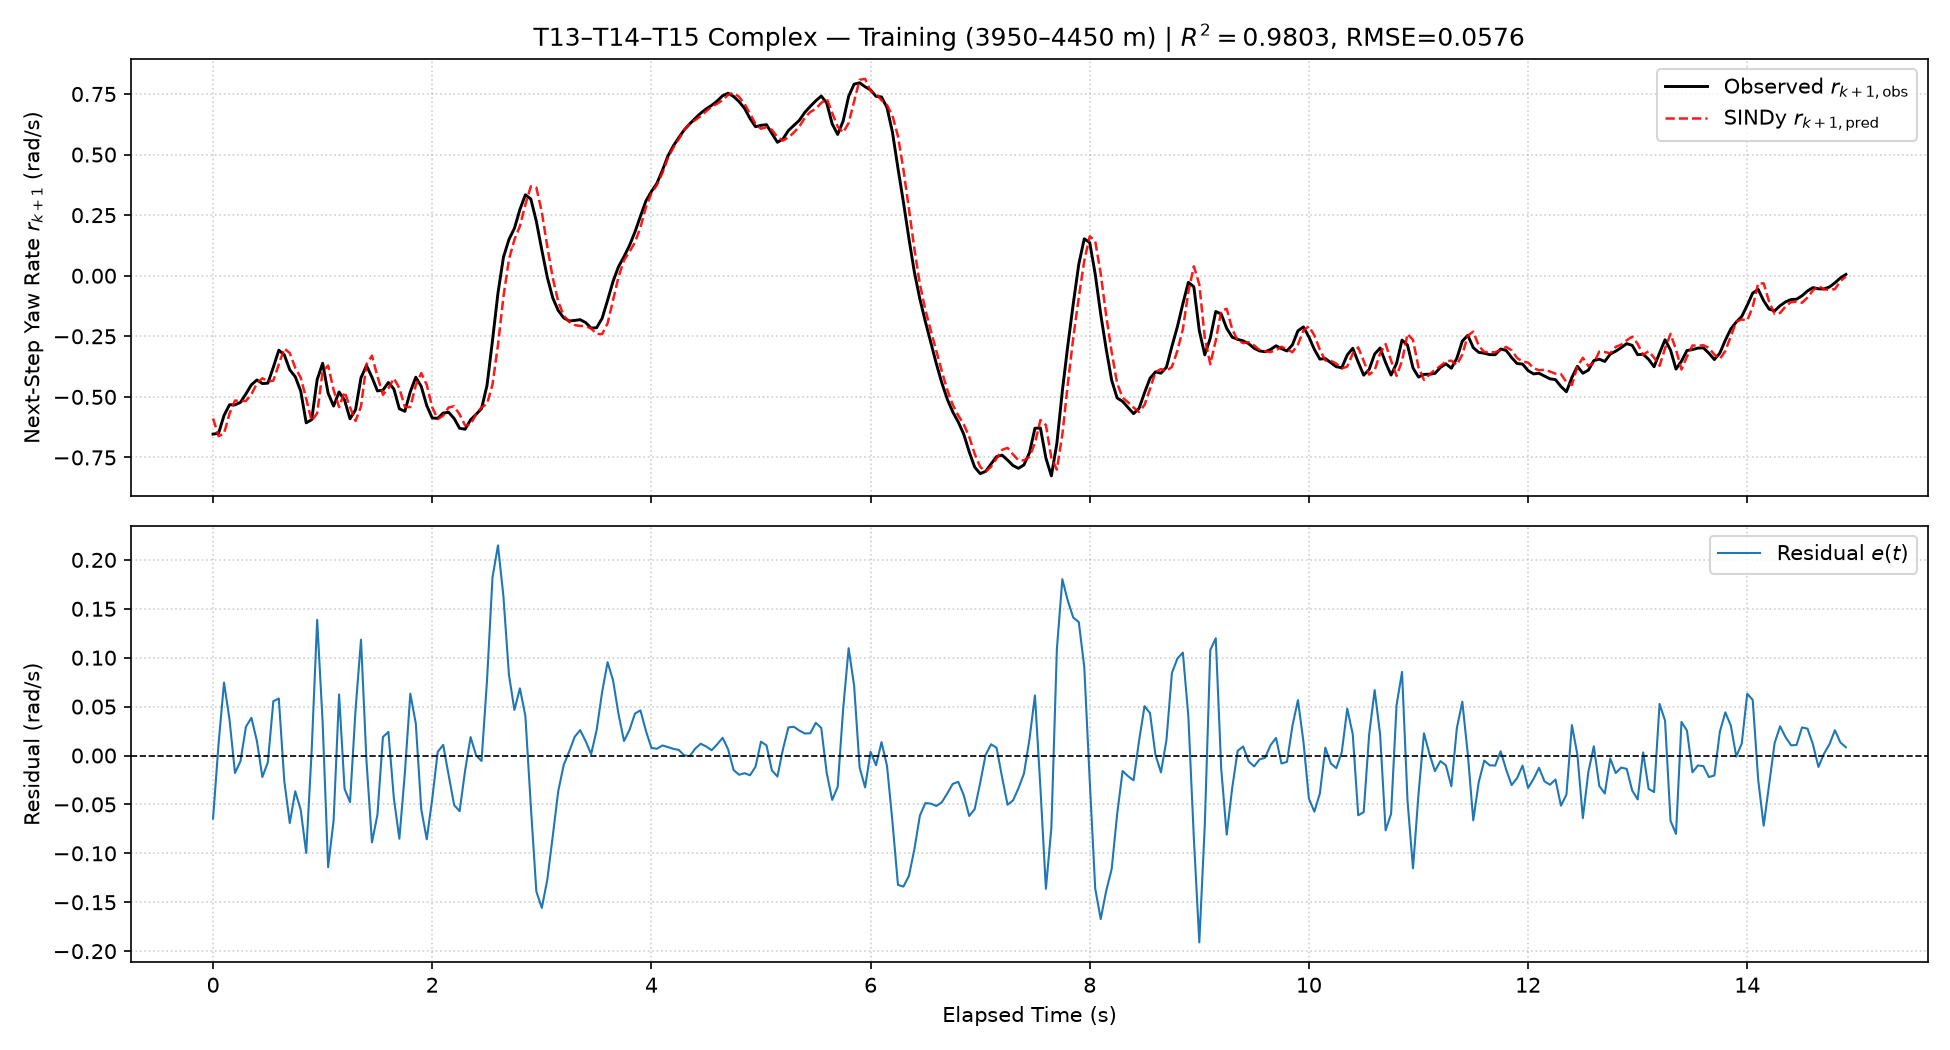

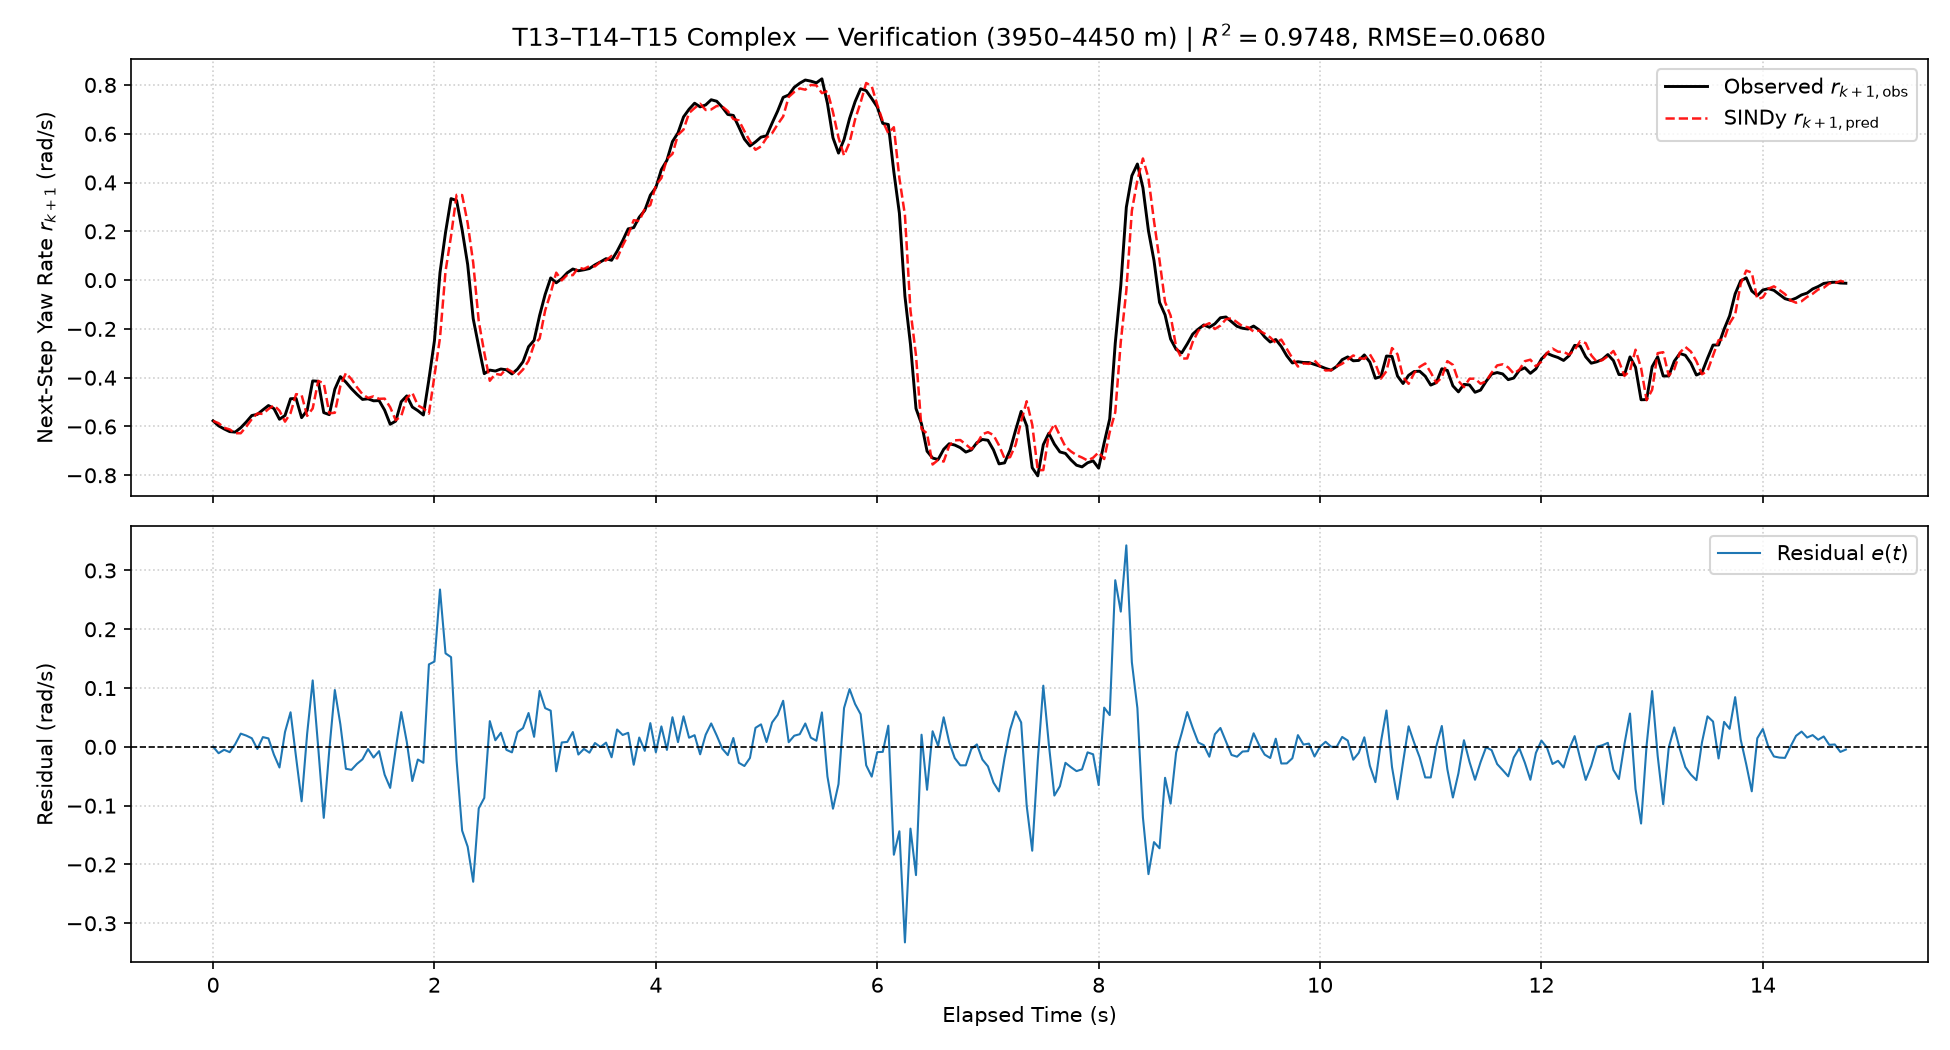

### Summary: Full Lap vs. Corner-Specific Fits

,Segment,Distance (m),Train Samples,Train R2,Train RMSE,Verif Samples,Verif R2,Verif RMSE,Identified ODE
0,Full Lap,0–4657,2130,0.9865,0.0393,2129,0.9829,0.0454,r_{k+1} = +1.0710 * r_k +0.0063 * a_y_k -0.006...
1,T3 (Renault),850–1450,285,0.9834,0.0420,288,0.9771,0.0513,r_{k+1} = +1.2791 * r_k +0.0086 * a_y_k -0.009...
2,T4 (Repsol),1450–1850,187,0.9808,0.0293,185,0.9691,0.0393,r_{k+1} = +1.2626 * r_k +0.0006 * a_y_k -0.005...
3,T5 (Seat),1850–2250,219,0.9875,0.0364,218,0.9866,0.0379,r_{k+1} = +1.2136 * r_k -0.0061 * a_y_k +0.003...
4,T13–T14–T15 Complex,3950–4450,301,0.9803,0.0576,298,0.9748,0.0680,r_{k+1} = +1.0037 * r_k +0.0181 * a_y_k -0.015...


In [5]:
corner_specs = [
    ("T3_Renault", "T3 (Renault)", 850.0, 1450.0),
    ("T4_Repsol", "T4 (Repsol)", 1450.0, 1850.0),
    ("T5_Seat", "T5 (Seat)", 1850.0, 2250.0),
    ("T13_T14_T15_Complex", "T13–T14–T15 Complex", 3950.0, 4450.0),
]

corner_dir = out_dir / "corners"
corner_dir.mkdir(parents=True, exist_ok=True)

corner_rows = []
for slug, label, s_m, e_m in corner_specs:
    sub_train = df_train[(df_train["LAP_DIST_M"] >= s_m) & (df_train["LAP_DIST_M"] <= e_m)].reset_index(drop=True)
    sub_ver = df_ver[(df_ver["LAP_DIST_M"] >= s_m) & (df_ver["LAP_DIST_M"] <= e_m)].reset_index(drop=True)

    f_tr = library.build(sub_train)
    f_va = library.build(sub_ver)

    c_model = fit_yaw_sindy(f_tr, cfg.modeling)
    e_tr = evaluate_model(c_model, f_tr)
    e_va = evaluate_model(c_model, f_va, ref_mean=e_tr.residual_mean, ref_std=e_tr.residual_std)

    p_tr = plot_yaw_acceleration_fit(
        sub_train,
        e_tr,
        title=f"{label} — Training ({s_m:.0f}–{e_m:.0f} m)",
        save_path=corner_dir / f"{slug}_train.png",
    )
    p_va = plot_yaw_acceleration_fit(
        sub_ver,
        e_va,
        title=f"{label} — Verification ({s_m:.0f}–{e_m:.0f} m)",
        save_path=corner_dir / f"{slug}_verification.png",
    )

    corner_rows.append({
        "Segment": label,
        "Distance (m)": f"{s_m:.0f}–{e_m:.0f}",
        "Train Samples": len(sub_train),
        "Train R2": round(e_tr.r2, 4),
        "Train RMSE": round(e_tr.rmse, 4),
        "Verif Samples": len(sub_ver),
        "Verif R2": round(e_va.r2, 4),
        "Verif RMSE": round(e_va.rmse, 4),
        "Identified ODE": c_model.format_equation(precision=4),
    })

    display(Markdown(f"### {label} (`{s_m:.0f}–{e_m:.0f} m`)"))
    print("Identified ODE:", c_model.format_equation())
    print(f"Training R^2 = {e_tr.r2:.4f}, RMSE = {e_tr.rmse:.4f} | Verification R^2 = {e_va.r2:.4f}, RMSE = {e_va.rmse:.4f}")
    display(Image(filename=str(p_tr)))
    display(Image(filename=str(p_va)))

display(Markdown("### Summary: Full Lap vs. Corner-Specific Fits"))
full_row = {
    "Segment": "Full Lap",
    "Distance (m)": "0–4657",
    "Train Samples": len(df_train),
    "Train R2": round(train_eval.r2, 4),
    "Train RMSE": round(train_eval.rmse, 4),
    "Verif Samples": len(df_ver),
    "Verif R2": round(ver_eval.r2, 4),
    "Verif RMSE": round(ver_eval.rmse, 4),
    "Identified ODE": full_model.format_equation(precision=4),
}
display(pd.DataFrame([full_row] + corner_rows))